In [1]:
"""
validate_iptcr.py: is the iptcr from mvi_pipeline.py any good?
 
Compares the pipeline's iptcr_results.csv with:
  A) REFERENCE scores you already have (e.g. manual / older iptcr in Scores.csv)   -> agreement
  B) the clinical Excel (Banff ptc, g, AMR, DSA strength)                          -> clinical validity
     The Delsante 2019 paper found iptcr rises with ptc and with DSA strength; a working model should too.
 
Writes to OUTPUT_DIR: validation_summary.txt (plain-language verdicts), merged_data.csv and plots.
 
    python validate_iptcr.py
"""
import os
import re
import json
 
import numpy as np
import pandas as pd
from scipy import stats

In [2]:
RESULTS_CSV   = "/home/pvempati/MVI_test/mvi_iptcr/iptcr_results.csv"   # = WORK_DIR of mvi_pipeline + /iptcr_results.csv
OUTPUT_DIR    = "/home/pvempati/MVI_test/mvi_iptcr/validation"
CLINICAL_XLSX = "/orange/pinaki.sarder/Davy_Jones_Locker/Transplant_R01/MVI_Dual_Stained(Acute)/MVI_DeID_0260210.xlsx"
REFERENCE_CSV = None        # or the path to Scores.csv, if you want to compare with older scores


# A) existing iptcr scores (optional). None = skip.
REFERENCE_CSV = None                 # e.g. "/blue/<group>/<gatorlink>/Scores.csv"
REFERENCE_ID_COLUMN = None           # None = first column
REFERENCE_SCORE_COLUMN = None        # None = first column whose name contains "iptcr" (not "predicted")
 
# B) clinical Excel (optional). None = skip.
# CLINICAL_XLSX = "/blue/<group>/<gatorlink>/MVI_DeID_0260210.xlsx"
CLINICAL_HEADER_ROW = 1              # MVI file: column names on the 2nd row
CLINICAL_ID_COLUMN = "DeID"
PTC_COLUMN = "ptc"
G_COLUMN = "g"
AMR_COLUMN = "AMR"
DSA_STRENGTH_COLUMN = "Strength.1"   # "Strength" at biopsy (pandas renames the 2nd "Strength" to "Strength.1")
 
# which pipeline columns to test (main rule first)
SCORE_COLUMNS = ["iptcr", "iptcr_pct3", "iptcr_pct8", "iptcr_pct15"]

In [3]:
# =================================================================== helpers
ID_PATTERN = re.compile(r"JHH[\s_-]*DS[\s_-]*0*(\d+)", re.IGNORECASE)
 
 
def key(name):
    """Same matching key as mvi_pipeline.slide_key."""
    m = ID_PATTERN.search(str(name))
    if m:
        return f"JHH_DS_{int(m.group(1))}"
    base = os.path.basename(str(name))
    while os.path.splitext(base)[1]:
        base = os.path.splitext(base)[0]
    base = re.sub(r"\s*-\s*\d{4}-\d{2}-\d{2}.*$", "", base)
    base = re.sub(r"cd34\s*[-_ ]?\s*(lca|cd45)", "", base, flags=re.I)
    return re.sub(r"[^a-z0-9]", "", base.lower())
 
 
def num(v):
    """'1?' -> 1.0, '2.5' -> 2.5, '' -> nan."""
    m = re.search(r"-?\d+(\.\d+)?", str(v))
    return float(m.group(0)) if m else np.nan
 
 
def auc(scores, labels):
    """ROC AUC via Mann-Whitney U (no sklearn needed)."""
    s, y = np.asarray(scores, float), np.asarray(labels, bool)
    pos, neg = s[y], s[~y]
    if len(pos) == 0 or len(neg) == 0:
        return np.nan, len(pos), len(neg)
    u = stats.mannwhitneyu(pos, neg, alternative="two-sided").statistic
    return u / (len(pos) * len(neg)), len(pos), len(neg)
 
 
def strength(r):
    r = abs(r)
    return "strong" if r >= 0.7 else "moderate" if r >= 0.4 else "weak" if r >= 0.2 else "none"
 

In [4]:
# =================================================================== main
def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
 
    res = pd.read_csv(RESULTS_CSV)
    res = res[res["status"] == "ok"].copy()
    res["key"] = res["slide"].map(key)
    cols = [c for c in SCORE_COLUMNS if c in res.columns]
    # several slides per case (e.g. 2 stains) -> mean per case
    pred = res.groupby("key")[cols + ["n_ptc_counted"]].mean()
    lines = [f"Pipeline results: {len(res)} slides, {len(pred)} cases", ""]
    merged = pred.copy()
 
    # ---------------- A) agreement with existing scores
    if REFERENCE_CSV:
        ref = pd.read_csv(REFERENCE_CSV)
        idc = REFERENCE_ID_COLUMN or ref.columns[0]
        sc = REFERENCE_SCORE_COLUMN or next(c for c in ref.columns
                                             if "iptcr" in str(c).lower() and "predicted" not in str(c).lower())
        ref["key"] = ref[idc].map(key)
        ref["reference_iptcr"] = pd.to_numeric(ref[sc], errors="coerce")
        merged = merged.join(ref.groupby("key")["reference_iptcr"].mean(), how="left")
        both = merged.dropna(subset=["reference_iptcr"])
        lines += [f"A) AGREEMENT WITH EXISTING SCORES ({REFERENCE_CSV}, column {sc!r})",
                  f"   matched cases: {len(both)}"]
        if len(both) >= 3:
            for c in cols:
                d = both[[c, "reference_iptcr"]].dropna()
                r, p = stats.pearsonr(d[c], d["reference_iptcr"])
                rho, ps = stats.spearmanr(d[c], d["reference_iptcr"])
                diff = d[c] - d["reference_iptcr"]
                lines.append(f"   {c:12} Pearson r={r:.2f} ({strength(r)}, p={p:.3g})  Spearman rho={rho:.2f}  "
                             f"mean abs error={diff.abs().mean():.3f}  bias={diff.mean():+.3f}  "
                             f"95% limits {diff.mean() - 1.96 * diff.std():+.3f} to {diff.mean() + 1.96 * diff.std():+.3f}")
            d = both[[cols[0], "reference_iptcr"]].dropna()
            fig, ax = plt.subplots(1, 2, figsize=(11, 5))
            ax[0].scatter(d["reference_iptcr"], d[cols[0]])
            lim = [0, max(d.max().max(), 0.01) * 1.05]
            ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("reference iptcr"); ax[0].set_ylabel(f"pipeline {cols[0]}")
            ax[0].set_title("Agreement")
            m, dd = (d[cols[0]] + d["reference_iptcr"]) / 2, d[cols[0]] - d["reference_iptcr"]
            ax[1].scatter(m, dd); ax[1].axhline(dd.mean(), color="k")
            for s in (-1.96, 1.96):
                ax[1].axhline(dd.mean() + s * dd.std(), color="r", ls="--")
            ax[1].set_xlabel("mean of the two"); ax[1].set_ylabel("pipeline - reference"); ax[1].set_title("Bland-Altman")
            fig.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "agreement_reference.png"), dpi=150)
        lines.append("")
 
    # ---------------- B) clinical validity
    if CLINICAL_XLSX:
        cl = pd.read_excel(CLINICAL_XLSX, header=CLINICAL_HEADER_ROW)
        cl.columns = [str(c).strip() for c in cl.columns]
        cl["key"] = cl[CLINICAL_ID_COLUMN].map(key)
        cl = cl.drop_duplicates("key").set_index("key")
        add = pd.DataFrame(index=cl.index)
        for name, col in (("banff_ptc", PTC_COLUMN), ("banff_g", G_COLUMN), ("amr", AMR_COLUMN)):
            if col in cl.columns:
                add[name] = cl[col].map(num)
        if DSA_STRENGTH_COLUMN in cl.columns:
            add["dsa_strength_at_biopsy"] = cl[DSA_STRENGTH_COLUMN].astype(str).str.strip().replace({"nan": ""})
        merged = merged.join(add, how="left")
        lines += ["B) CLINICAL VALIDITY (clinical Excel)",
                  f"   cases with clinical data: {merged['banff_ptc'].notna().sum() if 'banff_ptc' in merged else 0}"]
        for target in ("banff_ptc", "banff_g"):
            if target not in merged:
                continue
            for c in cols:
                d = merged[[c, target]].dropna()
                if len(d) >= 5:
                    rho, p = stats.spearmanr(d[c], d[target])
                    lines.append(f"   {c:12} vs {target:9} Spearman rho={rho:+.2f} ({strength(rho)}, p={p:.3g}, n={len(d)})")
        if "banff_ptc" in merged:
            for c in cols:
                d = merged[[c, "banff_ptc"]].dropna()
                a, npos, nneg = auc(d[c], d["banff_ptc"] >= 2)
                lines.append(f"   {c:12} AUC for Banff ptc >= 2: {a:.2f} (n={npos} vs {nneg})")
        if "amr" in merged:
            for c in cols:
                d = merged[[c, "amr"]].dropna()
                a, npos, nneg = auc(d[c], d["amr"] >= 1)
                lines.append(f"   {c:12} AUC for AMR (>= 1): {a:.2f} (n={npos} vs {nneg})")
        if "dsa_strength_at_biopsy" in merged:
            d = merged[[cols[0], "dsa_strength_at_biopsy"]].dropna()
            d = d[d["dsa_strength_at_biopsy"] != ""]
            groups = {g: v[cols[0]].values for g, v in d.groupby("dsa_strength_at_biopsy") if len(v) >= 3}
            if len(groups) >= 2:
                h, p = stats.kruskal(*groups.values())
                lines.append(f"   {cols[0]} by DSA strength at biopsy (Kruskal-Wallis p={p:.3g}): " +
                             ", ".join(f"{g}: median {np.median(v):.2f} (n={len(v)})" for g, v in groups.items()))
        if "banff_ptc" in merged:
            d = merged[[cols[0], "banff_ptc"]].dropna()
            d["grade"] = d["banff_ptc"].round().clip(0, 3).astype(int)
            fig, ax = plt.subplots(figsize=(6, 5))
            data = [d.loc[d["grade"] == g, cols[0]].values for g in range(4)]
            ax.boxplot(data)                         # (labels set separately: works on old and new matplotlib)
            ax.set_xticks(range(1, 5), [f"ptc {g}\n(n={len(x)})" for g, x in enumerate(data)])
            ax.set_ylabel(f"pipeline {cols[0]}"); ax.set_title("iptcr by pathologist Banff ptc grade")
            fig.tight_layout(); fig.savefig(os.path.join(OUTPUT_DIR, "iptcr_by_banff_ptc.png"), dpi=150)
        lines.append("")
 
    lines += ["HOW TO READ THIS",
              "   r / rho: 0.7+ strong, 0.4-0.7 moderate, 0.2-0.4 weak, below 0.2 no relationship.",
              "   AUC: 0.5 = no better than chance, 0.7 acceptable, 0.8 good, 0.9 excellent.",
              "   A working model: moderate-to-strong agreement with reference iptcr, iptcr rising with Banff ptc",
              "   (positive rho, higher boxes for higher grades) and with DSA strength, as in Delsante et al. 2019.",
              "   Compare the rows: the iptcr rule with the best numbers is the one to use going forward.",
              "   Few matched cases (< ~20) means the numbers are uncertain; look at the p-values."]
    merged.to_csv(os.path.join(OUTPUT_DIR, "merged_data.csv"))
    text = "\n".join(lines)
    with open(os.path.join(OUTPUT_DIR, "validation_summary.txt"), "w") as fh:
        fh.write(text)
    print(text)
    print(f"\nSaved to {OUTPUT_DIR}")
 
 
if __name__ == "__main__":
    main()

Pipeline results: 11 slides, 11 cases

B) CLINICAL VALIDITY (clinical Excel)
   cases with clinical data: 10
   iptcr        vs banff_ptc Spearman rho=-0.11 (none, p=0.757, n=10)
   iptcr_pct3   vs banff_ptc Spearman rho=-0.25 (weak, p=0.491, n=10)
   iptcr_pct8   vs banff_ptc Spearman rho=-0.25 (weak, p=0.491, n=10)
   iptcr_pct15  vs banff_ptc Spearman rho=-0.27 (weak, p=0.451, n=10)
   iptcr        vs banff_g   Spearman rho=-0.62 (moderate, p=0.0575, n=10)
   iptcr_pct3   vs banff_g   Spearman rho=-0.60 (moderate, p=0.0679, n=10)
   iptcr_pct8   vs banff_g   Spearman rho=-0.60 (moderate, p=0.0679, n=10)
   iptcr_pct15  vs banff_g   Spearman rho=-0.55 (moderate, p=0.101, n=10)
   iptcr        AUC for Banff ptc >= 2: 0.44 (n=9 vs 1)
   iptcr_pct3   AUC for Banff ptc >= 2: 0.44 (n=9 vs 1)
   iptcr_pct8   AUC for Banff ptc >= 2: 0.44 (n=9 vs 1)
   iptcr_pct15  AUC for Banff ptc >= 2: 0.33 (n=9 vs 1)
   iptcr        AUC for AMR (>= 1): 0.44 (n=5 vs 5)
   iptcr_pct3   AUC for AMR (>= 1): 

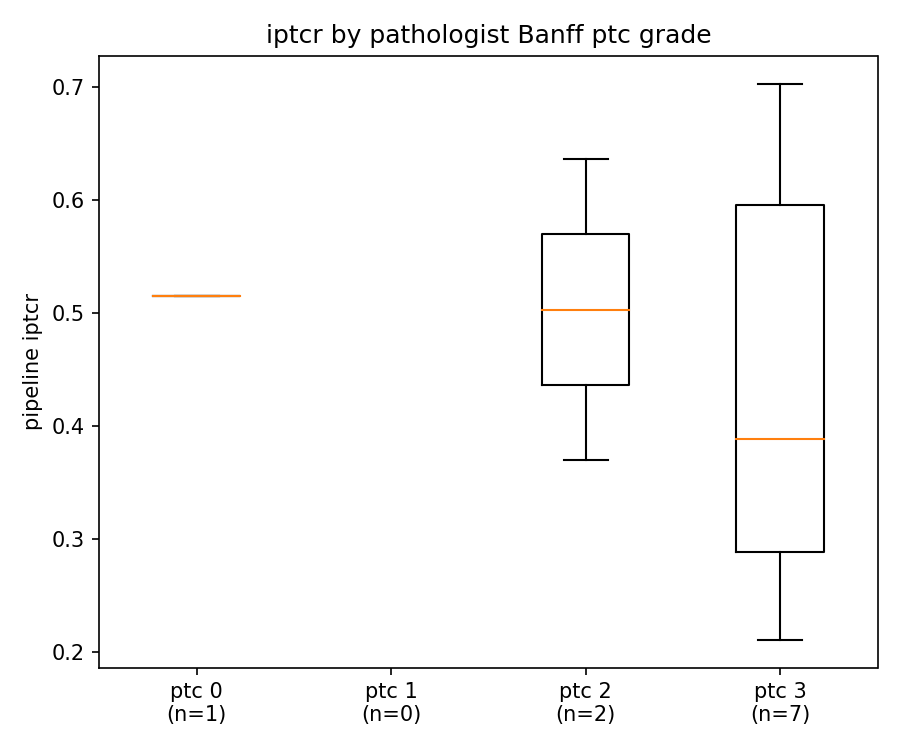

In [5]:
from IPython.display import Image, display
import os
for f in ("iptcr_by_banff_ptc.png", "agreement_reference.png"):
    p = os.path.join(OUTPUT_DIR, f)
    if os.path.exists(p):
        display(Image(p))